### Professional development formats and assessment self-efficacy among lower-secondary teachers (ISCED 2)

#### An analysis of TALIS 2024 data | Netherlands

*Fatima Mashood | May 2026*


**Data source:** OECD Teaching and Learning International Survey (TALIS) 2024  
https://webfs.oecd.org/talis/index.html

In [1]:
# Step 01: Imports and configuration

# pandas for data loading, filtering, and analysis
# numpy for handling numeric missing values (NaN)
# pathlib for clean cross-platform file paths
# re for regular expressions (variable name parsing)

import pandas as pd
import numpy as np
from pathlib import Path
import re

# Folder holding the TALIS 2024 teacher files (not included in this repo; see README, "Get the data").
# Override with the TALIS_DATA_DIR environment variable if your copy lives elsewhere.
import os
DATA_DIR = Path(os.environ.get("TALIS_DATA_DIR", "./datasets"))

def find_file(name):
    """Find a file anywhere under DATA_DIR (the OECD zip unpacks into nested folders)."""
    hits = sorted(DATA_DIR.rglob(name)) if DATA_DIR.exists() else []
    return hits[0] if hits else None

CSV_PATH = find_file("ttgintt4.csv")
SAV_PATH = find_file("ttgintt4.sav")

for name, path in [("ttgintt4.csv", CSV_PATH), ("ttgintt4.sav", SAV_PATH)]:
    print(f"{'✓' if path else '✗ MISSING'}  {name}" + (f"  ->  {path}" if path else ""))

if not (CSV_PATH and SAV_PATH):
    raise FileNotFoundError(
        f"TALIS 2024 teacher files not found under {DATA_DIR.resolve()}. "
        "Download them from the OECD TALIS 2024 data page (README, 'Get the data') and place "
        "ttgintt4.csv and ttgintt4.sav anywhere under ./datasets/, or set TALIS_DATA_DIR."
    )


✓  ttgintt4.csv  ->  ./datasets/ttgintt4.csv
✓  ttgintt4.sav  ->  ./datasets/ttgintt4.sav


In [2]:
# Step 02: Load the main teacher file, filter to Netherlands lower-secondary teachers
# (CNTRY == "NLD" and IDCNTPOP == "NLD2"; NLD1 = ISCED 1 primary teachers, excluded)

# The full file is ~278k rows × 630 columns (too large to load entirely)
# Using chunked reading: load 50,000 rows at a time, keep only the NLD2 rows from each chunk.
# sep=";" TALIS CSVs use semicolons as separators (common in European data).

nld_chunks = []

for chunk in pd.read_csv(CSV_PATH, sep=";", chunksize=50_000):
    nld_chunks.append(chunk[(chunk["CNTRY"] == "NLD") & (chunk["IDCNTPOP"] == "NLD2")])

nld = pd.concat(nld_chunks, ignore_index=True)

print(f"NLD2 subset: {nld.shape[0]:,} rows × {nld.shape[1]:,} columns")
print(f"\nFirst 10 rows, first 10 columns:")
nld.iloc[:10, :10]


NLD2 subset: 1,271 rows × 630 columns

First 10 rows, first 10 columns:


,CNTRY,IDCNTRY,IDCNTPOP,IDSCHOOL,IDTEACH,IDTQUEST,IDLANG_TQ,ITMODE_TQ,TT4G01,TT4G04
0,NLD,528,NLD2,2001,200101,3,12,1,8,2
1,NLD,528,NLD2,2001,200102,1,12,1,8,1
2,NLD,528,NLD2,2001,200103,2,12,1,8,1
3,NLD,528,NLD2,2001,200104,3,12,1,8,1
4,NLD,528,NLD2,2001,200105,1,12,1,8,1
5,NLD,528,NLD2,2001,200106,2,12,1,8,1
6,NLD,528,NLD2,2001,200107,3,12,1,8,2
7,NLD,528,NLD2,2001,200108,1,12,1,8,2
8,NLD,528,NLD2,2001,200109,2,12,1,8,9
9,NLD,528,NLD2,2001,200111,1,12,1,8,2


In [3]:
# Step 03: Initial structural checks

# Understand basic structure and quality of NLD subset
# Data types
# Missing data and values
# Sampling weight column (TCHWGT)
# Unique teacher IDs (IDSCHOOL + IDTEACH)

print("01: Column data types (first 20 columns)")
print(nld.dtypes.head(20))
print()

print("02: Missing data- columns with >20% missing (top 10)")
missing_pct = nld.isnull().mean().sort_values(ascending=False)
print(missing_pct[missing_pct > 0.20].head(10).apply(lambda x: f"{x:.1%}"))
print()

print("03: Sampling weight column")
if "TCHWGT" in nld.columns:
    print(f"TCHWGT found. Range: {nld['TCHWGT'].min():.2f} – {nld['TCHWGT'].max():.2f}")
    print(f"Sum of weights: {nld['TCHWGT'].sum():,.0f}  (≈ estimated NLD teacher population)")
else:
    print("TCHWGT not found — check column list")
print()

print("04: Unique teacher IDs?")
n_rows = len(nld)
n_unique = nld[["IDSCHOOL", "IDTEACH"]].drop_duplicates().shape[0]
print(f"Rows: {n_rows} | Unique IDSCHOOL+IDTEACH combos: {n_unique}")
print("Unique" if n_rows == n_unique else "DUPLICATES DETECTED")


01: Column data types (first 20 columns)
CNTRY          str
IDCNTRY      int64
IDCNTPOP       str
IDSCHOOL     int64
IDTEACH      int64
IDTQUEST     int64
IDLANG_TQ    int64
ITMODE_TQ    int64
TT4G01       int64
TT4G04       int64
TT4G06A      int64
TT4G06B      int64
TT4G06C      int64
TT4G06D      int64
TT4G06E      int64
TT4G06F      int64
TT4G07A      int64
TT4G07B      int64
TT4G07C      int64
TT4G07D      int64
dtype: object

02: Missing data- columns with >20% missing (top 10)
Series([], dtype: float64)

03: Sampling weight column
TCHWGT found. Range: 1.42 – 178.78
Sum of weights: 58,097  (≈ estimated NLD teacher population)

04: Unique teacher IDs?
Rows: 1271 | Unique IDSCHOOL+IDTEACH combos: 1271
Unique


In [4]:
# Step 04: Recode TALIS sentinel missing values to NaN 

# TALIS uses sentinel codes (special numbers) for missing values
# Replace with NaN pre-analysis on copy file (nld_clean) to preserve original data (nld)

MISSING_CODES = {8, 9, 96, 97, 98, 99, 996, 997, 998, 999}

numeric_cols = nld.select_dtypes(include="number").columns

nld_clean = nld.copy()
for col in numeric_cols:
    nld_clean[col] = nld_clean[col].where(~nld_clean[col].isin(MISSING_CODES), other=np.nan)

nan_before = nld[numeric_cols].isna().sum().sum()
nan_after  = nld_clean[numeric_cols].isna().sum().sum()

print(f"Rows:          {len(nld_clean):,}  (unchanged — values replaced, no rows dropped)")
print(f"NaN before:    {nan_before:,}")
print(f"NaN after:     {nan_after:,}")
print(f"Cells recoded: {nan_after - nan_before:,}")


Rows:          1,271  (unchanged — values replaced, no rows dropped)
NaN before:    0
NaN after:     245,672
Cells recoded: 245,672


In [5]:
# Step 05: Extract variable labels from SPSS version (same source)

# The CSV file only has column names like "TT4G27J" which are meaningless without context.
# The SPSS (.sav) version of the same file embeds the full question text for every variable in its metadata. 
# Read metadata using pyreadstat.

# row_limit=1 loads one data row (enough to get all metadata) instead of all

import pyreadstat

_, meta = pyreadstat.read_sav(
    SAV_PATH,
    row_limit=1,
    apply_value_formats=False
)

# Build lookup: {column_name: "full question text"}
labels = dict(zip(meta.column_names, meta.column_labels))

print(f"Variables with labels: {len(labels)}")
print()

# Show specific target variables
targets = {
    "TT4G20A": "PD format: Courses / workshops / seminars",
    "TT4G20B": "PD format: Education conferences",
    "TT4G20C": "PD format: Formal qualification programme",
    "TT4G20D": "PD format: Visits to other schools",
    "TT4G20E": "PD format: Visits to business premises",
    "TT4G20F": "PD format: Lesson observation & reflection",
    "TT4G20G": "PD format: Coaching / mentoring",
    "TT4G20H": "PD format: Teacher networks",
    "TT4G20I": "PD format: Self-initiated learning",
    "TT4G27J": "OUTCOME: Self-efficacy — use a variety of assessment strategies",
    "TT4G21M": "CONTEXT: PD covered analysis and use of student assessments",
}

print(f"{'Variable':<10}  {'SPSS label (from codebook)':<65}  {'Our label'}")
print("-" * 130)
for col, our_label in targets.items():
    spss_label = labels.get(col, "NOT FOUND")
    print(f"{col:<10}  {spss_label:<65}  {our_label}")


Variables with labels: 630

Variable    SPSS label (from codebook)                                         Our label
----------------------------------------------------------------------------------------------------------------------------------
TT4G20A     Professional Learning/ Participation in PL activities/ Courses/seminars/workshops  PD format: Courses / workshops / seminars
TT4G20B     Professional Learning/ Participation in PL activities/ Education conferences  PD format: Education conferences
TT4G20C     Professional Learning/ Participation in PL activities/ Formal qualification programme  PD format: Formal qualification programme
TT4G20D     Professional Learning/ Participation in PL activities/ Visits to other schools  PD format: Visits to other schools
TT4G20E     Professional Learning/ Participation in PL activities/ Visits to business premises  PD format: Visits to business premises
TT4G20F     Professional Learning/ Participation in PL activities/ Reflections on lesson 

---
## Analysis

### Variable selection

**Outcome — `TT4G27J`:** "Self-efficacy in teaching / Use a variety of assessment strategies"  
4-point Likert: 1 = Not at all, 2 = To some extent, 3 = Quite a bit, 4 = A lot

**Predictors — `TT4G20A–I`:** "In the past 12 months, did you participate in…?" (1 = Yes in person, 2 = Yes online, 3 = Yes both, 4 = No; 1–3 are pooled as "Yes")  
Nine professional learning formats: courses/workshops, conferences, formal qualifications, school visits, business visits, lesson observation reflection, coaching, teacher networks, self-initiated learning

**Contextual descriptive — `TT4G21M`:** "PD covered: Analysis and use of student assessments" (1 = Yes, 2 = No)


In [6]:
# Analysis Step 01: Confirm variable coverage for NLD 

# Verify:
#   (a) All 9 PD format items and the outcome are present in the dataset
#   (b) Response counts (n valid)- need enough non-missing cases per group
#   (c) Recode: TT4G20x uses 1/2/3 = Yes (in person / online / both), 4 = No; convert to 1/0 later (Step B1)

# Note: TALIS can leave question blocks unadministered (code 8); an item with very low 'n' is flagged and excluded.
# Here TT4G20A has no valid NLD2 responses; all other PD items have n of about 1,210.

import pandas as pd
import numpy as np

# Define the variables
PD_COLS = {
    "TT4G20A": "Courses / workshops / seminars",
    "TT4G20B": "Education conferences",
    "TT4G20C": "Formal qualification programme",
    "TT4G20D": "Visits to other schools",
    "TT4G20E": "Visits to business premises",
    "TT4G20F": "Lesson observation & reflection",
    "TT4G20G": "Coaching / mentoring",
    "TT4G20H": "Teacher networks",
    "TT4G20I": "Self-initiated learning",
}
OUTCOME_COL = "TT4G27J"   # Self-efficacy: use a variety of assessment strategies
CONTEXT_COL = "TT4G21M"   # PD content covered: analysis and use of student assessments
WEIGHT_COL  = "TCHWGT"

# Check coverage
print(f"NLD sample: {len(nld_clean):,} teachers\n")
print(f"{'Variable':<12}  {'Label':<40}  {'n valid':>8}  {'% valid':>8}  {'% Yes':>8}")
print("-" * 82)

for col, label in PD_COLS.items():
    n_valid = nld_clean[col].notna().sum()
    pct_valid = n_valid / len(nld_clean) * 100
    # 1/2/3=Yes (in person / online / both), 4=No → pct Yes among valid responses
    pct_yes = nld_clean[col].isin([1, 2, 3]).sum() / n_valid * 100 if n_valid > 0 else np.nan
    flag = "LOW" if n_valid < 500 else ""
    print(f"{col:<12}  {label:<40}  {n_valid:>8,}  {pct_valid:>7.1f}%  {pct_yes:>7.1f}%{flag}")

print("-" * 82)
n_out = nld_clean[OUTCOME_COL].notna().sum()
print(f"\nOutcome {OUTCOME_COL} ({labels[OUTCOME_COL].split('/')[-1].strip()}):")
print(f"  n valid = {n_out:,} ({n_out/len(nld_clean)*100:.1f}%)")
print(f"  Mean = {nld_clean[OUTCOME_COL].mean():.3f}  |  Median = {nld_clean[OUTCOME_COL].median():.1f}")
print(f"  Distribution: { {int(k): int(v) for k, v in nld_clean[OUTCOME_COL].value_counts().sort_index().items()} }")

n_ctx = nld_clean[CONTEXT_COL].notna().sum()
pct_ctx_yes = (nld_clean[CONTEXT_COL] == 1).sum() / n_ctx * 100
print(f"\nContext {CONTEXT_COL} (PD covered assessment analysis):")
print(f"  n valid = {n_ctx:,} | % Yes (had assessment-content PD) = {pct_ctx_yes:.1f}%")


NLD sample: 1,271 teachers

Variable      Label                                      n valid   % valid     % Yes
----------------------------------------------------------------------------------
TT4G20A       Courses / workshops / seminars                   0      0.0%      nan%LOW
TT4G20B       Education conferences                        1,217     95.8%     42.6%
TT4G20C       Formal qualification programme               1,209     95.1%     19.5%
TT4G20D       Visits to other schools                      1,214     95.5%     23.8%
TT4G20E       Visits to business premises                  1,215     95.6%     20.3%
TT4G20F       Lesson observation & reflection              1,217     95.8%     69.0%
TT4G20G       Coaching / mentoring                         1,214     95.5%     35.9%
TT4G20H       Teacher networks                             1,213     95.4%     40.7%
TT4G20I       Self-initiated learning                      1,216     95.7%     53.8%
------------------------------------

## Step B: Descriptive Analysis

1. PD participation rates: what share of NLD lower-secondary teachers engaged in each format?
2. Outcome distribution: how is assessment self-efficacy spread across the 1–4 scale?

"What does professional learning look like for NLD lower-secondary teachers?"

In [7]:
# Step B1: PD participation rates and outcome distribution 

# TT4G20A–I: "Did you participate in [format] in the past 12 months?"
#   Original coding: 1 = Yes in person, 2 = Yes online, 3 = Yes both, 4 = No
#   (codebook value labels). We pool 1-3 as Yes (1) and recode 4 as No (0).

# TT4G27J: "Self-efficacy: Use a variety of assessment strategies"
# Scale: 1 = Not at all, 2 = To some extent, 3 = Quite a bit, 4 = A lot

# Recode PD format items to 0/1 (0=No, 1=Yes) 
pd_binary = {}
for col in PD_COLS:
    s = nld_clean[col]
    pd_binary[col] = s.map({1: 1, 2: 1, 3: 1, 4: 0})  # explicit map — leaves NaN as NaN

# PD participation rate table 
print("PD format participation rates — NLD lower-secondary teachers (TALIS 2024)")
print(f"{'Format':<40}  {'n responded':>12}  {'% participated':>14}")
print("-" * 72)
for col, label in PD_COLS.items():
    s = pd_binary[col]
    n = s.notna().sum()
    pct = s.mean() * 100
    print(f"{label:<40}  {n:>12,}  {pct:>13.1f}%")

# Outcome distribution 
out = nld_clean[OUTCOME_COL].dropna()
print(f"\nOutcome: {labels[OUTCOME_COL].split('/')[-1].strip()}")
print(f"n = {len(out):,}  |  Mean = {out.mean():.2f}  |  SD = {out.std():.2f}")
print()
print(f"{'Response':<30}  {'n':>6}  {'%':>6}")
print("-" * 45)
response_labels = {1: "1 – Not at all", 2: "2 – To some extent",
                   3: "3 – Quite a bit", 4: "4 – A lot"}
for code, resp_label in response_labels.items():
    n = (out == code).sum()
    print(f"{resp_label:<30}  {n:>6,}  {n/len(out)*100:>5.1f}%")


PD format participation rates — NLD lower-secondary teachers (TALIS 2024)
Format                                     n responded  % participated
------------------------------------------------------------------------
Courses / workshops / seminars                       0            nan%
Education conferences                            1,217           42.6%
Formal qualification programme                   1,209           19.5%
Visits to other schools                          1,214           23.8%
Visits to business premises                      1,215           20.3%
Lesson observation & reflection                  1,217           69.0%
Coaching / mentoring                             1,214           35.9%
Teacher networks                                 1,213           40.7%
Self-initiated learning                          1,216           53.8%

Outcome: Use a variety of assessment strategies
n = 1,179  |  Mean = 2.96  |  SD = 0.73

Response                             n       %
------

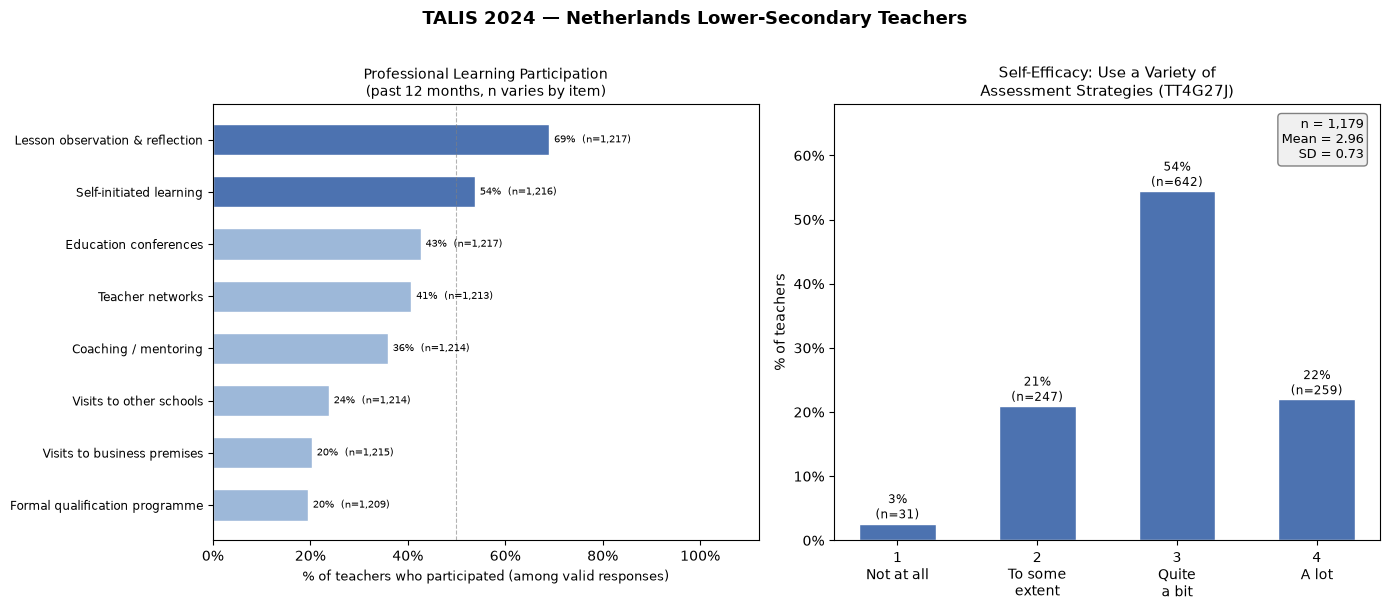

Figure saved: fig1_descriptive.png


In [8]:
# Step B2: Descriptive visualisations 

# Two charts:
#   Left: PD participation rates (% Yes per format, sorted, excluding empty items)
#   Right: Outcome variable distribution (% per response point)
#
# Note: TT4G20A (courses/workshops) has no valid responses for NLD, so it is excluded.
# TT4G20E (business visits) was answered by fewer teachers than the other items (see n labels).
# Participation rates are computed among teachers with a valid answer to each item.

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# Build participation rate dict, skipping variables with no data 
rates = {}
ns = {}
for col, label in PD_COLS.items():
    s = pd_binary[col]
    n = s.notna().sum()
    if n > 0:
        rates[label] = s.mean() * 100
        ns[label] = n

# Sort ascending so highest bar is at top
rates_sorted = dict(sorted(rates.items(), key=lambda x: x[1]))
ns_sorted    = {k: ns[k] for k in rates_sorted}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("TALIS 2024 — Netherlands Lower-Secondary Teachers",
             fontsize=13, fontweight="bold", y=1.01)

# Left: PD participation rates 
colors = ["#4C72B0" if v >= 50 else "#9DB8D9" for v in rates_sorted.values()]
bars = ax1.barh(list(rates_sorted.keys()), list(rates_sorted.values()),
                color=colors, edgecolor="white", height=0.6)

ax1.set_xlabel("% of teachers who participated (among valid responses)", fontsize=9)
ax1.set_title("Professional Learning Participation\n(past 12 months, n varies by item)", fontsize=10)
ax1.xaxis.set_major_formatter(mtick.PercentFormatter())
ax1.set_xlim(0, 112)
ax1.tick_params(axis="y", labelsize=8.5)
ax1.axvline(50, color="grey", linestyle="--", linewidth=0.8, alpha=0.6)

for bar, val, (lbl, n) in zip(bars, rates_sorted.values(), ns_sorted.items()):
    ax1.text(val + 1, bar.get_y() + bar.get_height() / 2,
             f"{val:.0f}%  (n={n:,})", va="center", fontsize=7.5)

# Right: Outcome distribution
out = nld_clean[OUTCOME_COL].dropna()
resp_labels = ["1\nNot at all", "2\nTo some\nextent", "3\nQuite\na bit", "4\nA lot"]
counts = [(out == i).sum() for i in [1, 2, 3, 4]]
pcts   = [c / len(out) * 100 for c in counts]

bars2 = ax2.bar(resp_labels, pcts, color="#4C72B0", edgecolor="white", width=0.55)
ax2.set_ylabel("% of teachers", fontsize=10)
ax2.set_title("Self-Efficacy: Use a Variety of\nAssessment Strategies (TT4G27J)", fontsize=11)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(0, 68)

for bar, pct, n in zip(bars2, pcts, counts):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
             f"{pct:.0f}%\n(n={n:,})", ha="center", fontsize=8.5)

ax2.text(0.97, 0.97, f"n = {len(out):,}\nMean = {out.mean():.2f}\nSD = {out.std():.2f}",
         transform=ax2.transAxes, ha="right", va="top", fontsize=9,
         bbox=dict(boxstyle="round,pad=0.3", facecolor="#f0f0f0", edgecolor="grey"))

plt.tight_layout()
plt.savefig("fig1_descriptive.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved: fig1_descriptive.png")


*Figure 1. PD participation rates (left) and assessment self-efficacy distribution (right) for NLD lower-secondary teachers (ISCED 2), TALIS 2024. Participation = any "Yes" answer (in person, online or both); rates are among teachers with a valid answer to each item, so n varies slightly by item. Unweighted. See Key Findings for interpretation.*

## Step C: Comparative Analysis

For each PD format, we compare mean assessment self-efficacy (`TT4G27J`) between teachers who **participated** (Yes: in person, online or both) and those who **did not** (No).

**Test choice: Mann-Whitney U:**
The outcome is a 4-point ordinal scale, so we cannot assume a normal distribution. Mann-Whitney U tests whether one group tends to score higher than the other without assuming interval-level measurement.

**Minimum group size threshold:**  
We only run a comparison where both Yes and No groups have **n ≥ 30**. All eight formats with data pass; courses/workshops (`TT4G20A`) has no valid responses for NLD.

**Effect size:**  
We report rank-biserial correlation (*r*) alongside p-values: *r* = 2U / (n_yes × n_no) − 1, so positive *r* means the Yes group tends to score higher. A p-value alone is insufficient; conventions: *r* ≈ 0.1 small, 0.3 medium, 0.5 large.

**Multiple comparisons:** eight tests are run with no formal adjustment. A Bonferroni threshold would be .05 / 8 ≈ .006.

In [9]:
# Step C1: Group comparisons | Mann-Whitney U tests 

# For each PD format:
#   - Split TT4G27J scores into Yes (participated) and No (did not) groups
#   - Skip any format where either group has n < 30
#   - Run Mann-Whitney U test (two-sided)
#   - Compute rank-biserial correlation as effect size:
#       r = (2 * U) / (n_yes * n_no) - 1
#     scipy's U is the statistic for the first sample (yes_scores), so
#     positive r = Yes group tends to score higher

from scipy import stats
import numpy as np

def fp(p):
    """Format a p-value; scientific notation below .001 so tiny values stay readable."""
    return f"{p:.1e}" if p < .001 else f"{p:.4f}"

MIN_N = 30   # minimum group size to run a comparison

outcome = nld_clean[OUTCOME_COL]

results = []
skipped = []

for col, label in PD_COLS.items():
    grp = pd_binary.get(col)
    if grp is None:
        continue

    # Align outcome and group membership (drop rows where either is NaN)
    combined = pd.DataFrame({"grp": grp, "outcome": outcome}).dropna()
    yes_scores = combined.loc[combined["grp"] == 1, "outcome"]
    no_scores  = combined.loc[combined["grp"] == 0, "outcome"]

    n_yes, n_no = len(yes_scores), len(no_scores)

    if n_yes < MIN_N or n_no < MIN_N:
        skipped.append((label, n_yes, n_no))
        continue

    u_stat, p_val = stats.mannwhitneyu(yes_scores, no_scores, alternative="two-sided")

    # Rank-biserial correlation effect size
    r = (2 * u_stat) / (n_yes * n_no) - 1

    results.append({
        "Format": label,
        "n Yes": n_yes,
        "Mean (Yes)": yes_scores.mean(),
        "n No": n_no,
        "Mean (No)": no_scores.mean(),
        "Difference": yes_scores.mean() - no_scores.mean(),
        "U": u_stat,
        "p": p_val,
        "r (effect)": r,
    })

# Print results table
print("Formats with sufficient group sizes (n ≥ 30 in both groups):\n")
print(f"{'Format':<38}  {'n Yes':>6}  {'M Yes':>6}  {'n No':>6}  {'M No':>6}  {'Diff':>6}  {'p':>7}  {'r':>6}")
print("-" * 95)
for row in results:
    sig = "**" if row["p"] < 0.01 else ("*" if row["p"] < 0.05 else "")
    print(f"{row['Format']:<38}  {row['n Yes']:>6,}  {row['Mean (Yes)']:>6.2f}  "
          f"{row['n No']:>6,}  {row['Mean (No)']:>6.2f}  {row['Difference']:>+6.2f}  "
          f"{fp(row['p']):>7}{sig}  {row['r (effect)']:>+6.3f}")

print("\n* p < .05   ** p < .01")

print(f"\nFormats excluded (n < {MIN_N} in one group):")
for lbl, ny, nn in skipped:
    print(f"  {lbl:<38}  n Yes={ny:,}  n No={nn}")


Formats with sufficient group sizes (n ≥ 30 in both groups):

Format                                   n Yes   M Yes    n No    M No    Diff        p       r
-----------------------------------------------------------------------------------------------
Education conferences                      497    3.06     672    2.89   +0.17  5.9e-05**  +0.124
Formal qualification programme             222    2.89     939    2.97   -0.08   0.1026  -0.064
Visits to other schools                    276    3.04     889    2.93   +0.11   0.0533  +0.070
Visits to business premises                238    3.03     929    2.94   +0.10   0.1059  +0.061
Lesson observation & reflection            802    2.98     367    2.91   +0.07   0.1697  +0.045
Coaching / mentoring                       421    2.99     744    2.94   +0.05   0.2492  +0.037
Teacher networks                           475    3.07     691    2.88   +0.20  1.4e-05**  +0.136
Self-initiated learning                    629    3.04     539    2.86

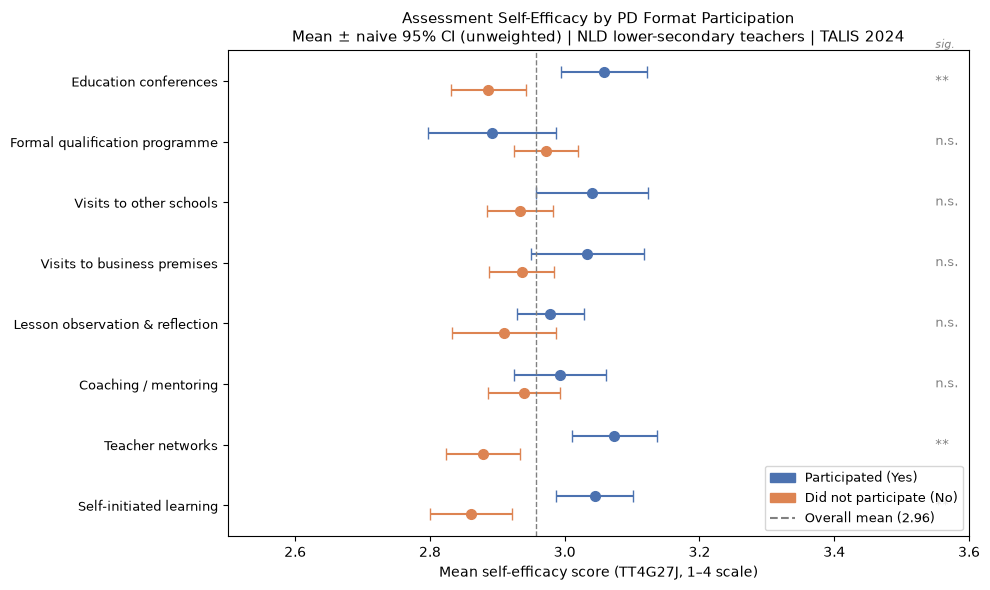

Figure saved: fig2_comparison.png


In [10]:
# Step C2: Visualising group comparisons 

# Dot-and-CI plot: mean TT4G27J (±95% CI) for Yes vs No within each format.
# 95% CI uses the standard error of the mean: CI = mean ± 1.96 * (SD / sqrt(n))
# Naive interval: ignores TALIS weights and the school/replicate design, so it is
# too narrow for population inference; read it as sample-level spread only.
# This shows both the point estimate and the uncertainty around it.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))

formats   = [r["Format"] for r in results]
y_pos     = np.arange(len(formats))
colors    = {"Yes": "#4C72B0", "No": "#DD8452"}

for i, row in enumerate(results):
    combined = pd.DataFrame({"grp": pd_binary[list(PD_COLS.keys())[
        list(PD_COLS.values()).index(row["Format"])]], "outcome": outcome}).dropna()

    for grp_val, grp_label, offset in [(1, "Yes", -0.15), (0, "No", +0.15)]:
        scores = combined.loc[combined["grp"] == grp_val, "outcome"]
        m  = scores.mean()
        se = scores.sem()
        ci = 1.96 * se

        ax.errorbar(m, i + offset, xerr=ci, fmt="o", color=colors[grp_label],
                    capsize=4, markersize=7, linewidth=1.5,
                    label=f"Participated ({grp_label})" if i == 0 else "")

# Axis formatting
ax.set_yticks(y_pos)
ax.set_yticklabels(formats, fontsize=9)
ax.set_xlabel("Mean self-efficacy score (TT4G27J, 1–4 scale)", fontsize=10)
ax.set_title("Assessment Self-Efficacy by PD Format Participation\n"
             "Mean ± naive 95% CI (unweighted) | NLD lower-secondary teachers | TALIS 2024", fontsize=11)
ax.set_xlim(2.5, 3.6)
ax.axvline(outcome.mean(), color="grey", linestyle="--", linewidth=1,
           label=f"Overall mean ({outcome.mean():.2f})")
ax.invert_yaxis()

# Significance annotations
for i, row in enumerate(results):
    sig = "n.s." if row["p"] >= 0.05 else ("**" if row["p"] < 0.01 else "*")
    ax.text(3.55, i, sig, va="center", fontsize=9, color="grey")

ax.text(3.55, -0.6, "sig.", va="center", fontsize=8, color="grey", style="italic")

yes_patch = mpatches.Patch(color=colors["Yes"], label="Participated (Yes)")
no_patch  = mpatches.Patch(color=colors["No"],  label="Did not participate (No)")
mean_line = plt.Line2D([0], [0], color="grey", linestyle="--", label=f"Overall mean ({outcome.mean():.2f})")
ax.legend(handles=[yes_patch, no_patch, mean_line], fontsize=9, loc="lower right")

plt.tight_layout()
plt.savefig("fig2_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved: fig2_comparison.png")


### Sensitivity check: design-based (weighted) mean differences

The Mann-Whitney tests above are unweighted. As a check, the table below gives the **weighted difference in mean self-efficacy** (Yes minus No) using `TCHWGT`, with standard errors from the 100 BRR replicate weights (`TRWGT1–100`, Fay's *k* = 0.5, variance multiplier 1 / (100 × 0.5²) = 0.04) and normal-theory p-values. It uses the same Yes/No definition and the same teachers as Step C1.

In [11]:
# Step C3: Design-based sensitivity check | weighted mean difference with BRR standard errors

from scipy.stats import norm

REP_COLS = [f"TRWGT{i}" for i in range(1, 101)]
BRR_MULT = 1 / (100 * (1 - 0.5) ** 2)   # Fay k = 0.5 -> 0.04

def wmean_diff(y, g, w):
    return np.average(y[g == 1], weights=w[g == 1]) - np.average(y[g == 0], weights=w[g == 0])

print(f"{'Format':<38}  {'n Yes':>6}  {'n No':>6}  {'W diff':>7}  {'SE':>6}  {'p':>7}  {'U-test p':>9}")
print("-" * 92)
for row in results:
    col = list(PD_COLS.keys())[list(PD_COLS.values()).index(row["Format"])]
    keep = pd_binary[col].notna() & outcome.notna()
    g = pd_binary[col][keep].values
    y = outcome[keep].values
    w = nld.loc[keep, "TCHWGT"].values            # raw weights, not the sentinel-recoded copy
    est = wmean_diff(y, g, w)
    reps = np.array([wmean_diff(y, g, nld.loc[keep, c].values) for c in REP_COLS])
    se = np.sqrt(BRR_MULT * ((reps - est) ** 2).sum())
    p_w = 2 * (1 - norm.cdf(abs(est / se)))
    print(f"{row['Format']:<38}  {int(g.sum()):>6,}  {int((1 - g).sum()):>6,}  {est:>+7.3f}  {se:>6.3f}  {fp(p_w):>7}  {fp(row['p']):>9}")


Format                                   n Yes    n No   W diff      SE        p   U-test p
--------------------------------------------------------------------------------------------
Education conferences                      497     672   +0.196   0.047  3.4e-05    5.9e-05
Formal qualification programme             222     939   -0.083   0.047   0.0794     0.1026
Visits to other schools                    276     889   +0.120   0.067   0.0758     0.0533
Visits to business premises                238     929   +0.066   0.076   0.3866     0.1059
Lesson observation & reflection            802     367   +0.073   0.059   0.2105     0.1697
Coaching / mentoring                       421     744   +0.023   0.045   0.6115     0.2492
Teacher networks                           475     691   +0.220   0.051  1.5e-05    1.4e-05
Self-initiated learning                    629     539   +0.198   0.048  3.4e-05    2.9e-05


## Step D: Research Brief
A concise summary of key findings, implications for practice, and suggestions for future research. This will be designed for policymakers and practitioners interested in leveraging PD to enhance assessment self-efficacy among teachers.

### Research Question

**Which professional development formats are associated with higher self-reported self-efficacy in using assessment strategies, among lower-secondary teachers in the Netherlands?**

Assessment self-efficacy (a teacher's confidence in their own ability to use a variety of assessment strategies) is considered a meaningful indicator of instructional quality. 

Professional development (PD) is one of the primary levers schools and systems use to build that capacity, and the landscape of PD formats is diverse; from structured courses and formal qualifications, to peer-led activities such as lesson observation, coaching, and teacher networks. 

Whether the format of PD, independent of its content, is associated with teachers' confidence in assessment practice remains an open research question.

My analysis uses TALIS 2024 survey data to examine that question for Dutch lower-secondary teachers.

#### Step C4: Confidence intervals and joint model (sensitivity)

Welch 95% CIs for each unadjusted mean difference, then one OLS model with all eight formats entered together (school-clustered standard errors, unweighted) to check whether the formats' associations hold when adjusted for each other. An ordered logit with the same predictors is run as a robustness check.

In [12]:
import statsmodels.api as sm

print(f"{'Format':<38}  {'Diff':>6}  {'95% CI (Welch)':>16}")
print("-" * 66)
for row in results:
    col = list(PD_COLS.keys())[list(PD_COLS.values()).index(row["Format"])]
    d = pd.DataFrame({"g": pd_binary[col], "y": outcome}).dropna()
    a, b = d.loc[d.g == 1, "y"], d.loc[d.g == 0, "y"]
    diff = a.mean() - b.mean()
    va, vb = a.var() / len(a), b.var() / len(b)
    se = np.sqrt(va + vb)
    dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    t = stats.t.ppf(0.975, dof)
    print(f"{row['Format']:<38}  {diff:>+6.2f}  [{diff - t * se:>+6.2f}, {diff + t * se:>+6.2f}]")

# Joint model: all eight formats together, school-clustered SEs (complete cases)
cols8 = [c for c in PD_COLS if pd_binary[c].notna().any()]
X = pd.DataFrame({PD_COLS[c]: pd_binary[c] for c in cols8})
dat = pd.concat([outcome.rename("y"), X], axis=1).dropna()
fit = sm.OLS(dat["y"], sm.add_constant(dat[list(X.columns)])).fit(
    cov_type="cluster", cov_kwds={"groups": nld.loc[dat.index, "IDSCHOOL"]})
print(f"\nJoint model (n = {len(dat):,}, school-clustered SEs)")
ci = fit.conf_int()
for name in X.columns:
    print(f"{name:<38}  b = {fit.params[name]:>+6.3f}  [{ci.loc[name, 0]:>+6.3f}, {ci.loc[name, 1]:>+6.3f}]  p = {fp(fit.pvalues[name])}")

# Robustness: ordered logit (treats the 1-4 outcome as ordinal), same predictors and clustering
from statsmodels.miscmodels.ordinal_model import OrderedModel
ol = OrderedModel(dat["y"].astype(int), dat[list(X.columns)], distr="logit").fit(
    method="bfgs", disp=0, cov_type="cluster", cov_kwds={"groups": nld.loc[dat.index, "IDSCHOOL"]})
print("\nOrdered logit: odds ratios")
for name in X.columns:
    print(f"{name:<38}  OR = {np.exp(ol.params[name]):>5.2f}  p = {fp(ol.pvalues[name])}")


Format                                    Diff    95% CI (Welch)
------------------------------------------------------------------
Education conferences                    +0.17  [ +0.09,  +0.26]
Formal qualification programme           -0.08  [ -0.19,  +0.03]
Visits to other schools                  +0.11  [ +0.01,  +0.20]
Visits to business premises              +0.10  [ -0.00,  +0.19]
Lesson observation & reflection          +0.07  [ -0.02,  +0.16]
Coaching / mentoring                     +0.05  [ -0.03,  +0.14]
Teacher networks                         +0.20  [ +0.11,  +0.28]
Self-initiated learning                  +0.18  [ +0.10,  +0.27]

Joint model (n = 1,135, school-clustered SEs)
Education conferences                   b = +0.126  [+0.035, +0.216]  p = 0.0064
Formal qualification programme          b = -0.104  [-0.213, +0.005]  p = 0.0609
Visits to other schools                 b = +0.051  [-0.048, +0.151]  p = 0.3124
Visits to business premises             b = +0.021  [-0.07

### Data and method

**Source:** OECD Teaching and Learning International Survey (TALIS) 2024, teacher-level international file (`ttgintt4`). TALIS is a large-scale, school-based international survey of teachers and school leaders. Data are publicly available at [webfs.oecd.org/talis](https://webfs.oecd.org/talis/index.html).

**Sample:** Netherlands lower-secondary teachers (ISCED 2): `CNTRY = "NLD"` and `IDCNTPOP = "NLD2"` (`IDPOP = 2`). The Netherlands file also contains 1,305 primary (ISCED 1, `NLD1`) teachers, who are excluded. After filtering and removing sentinel missing-value codes (8, 9, 96–99, 996–999), the working sample comprises **n = 1,271 teachers** across **630 variables** (1,179 with a valid outcome).

**Variables:**

| Role | Code | Description |
|---|---|---|
| Outcome | `TT4G27J` | Self-efficacy: "Use a variety of assessment strategies" (1–4 scale) |
| Predictors | `TT4G20A–I` | "In the past 12 months, did you participate in [format]?" 1 = Yes, in person; 2 = Yes, online; 3 = Yes, both; 4 = No. Recoded to Yes (1–3) vs No (4). |

Nine PD formats were considered: courses/workshops, education conferences, formal qualification programmes, visits to other schools, visits to business premises, lesson observation and reflection, coaching/mentoring, teacher networks, and self-initiated learning.

**Analytical approach:**

1. **Data quality checks:** verified variable coverage, sentinel recode, and unique respondent IDs.
2. **Descriptive analysis:** participation rates per format; distribution of outcome variable including mean and SD.
3. **Comparative analysis:** for each format, teachers who participated (Yes) were compared to those who did not (No) on mean `TT4G27J` using a Mann-Whitney U test (non-parametric; chosen because the outcome is a 4-point ordinal scale). Effect size was quantified using the **rank-biserial correlation** (*r*). Comparisons were run where both groups had *n* ≥ 30.

The main tests are **unweighted** and describe this sample, not the national teacher population. A design-based sensitivity check (weighted mean differences with BRR standard errors) is reported after Figure 2.

### Key Findings

#### Descriptive (Figure 1)

Participation varies widely by format. Among Dutch lower-secondary teachers with a valid answer, lesson observation and reflection is the most common (69%), followed by self-initiated learning (54%), education conferences (43%), teacher networks (41%), coaching/mentoring (36%), visits to other schools (24%), visits to business premises (20%) and formal qualification programmes (20%). Courses/workshops (`TT4G20A`) has no valid responses for NLD and is not reported.

Assessment self-efficacy is **fairly high**, with a mean of **2.96 out of 4** (SD = 0.73, n = 1,179). The distribution is concentrated in the upper half of the scale: 54.5% of teachers report "Quite a bit" of confidence and 22.0% report "A lot"; 20.9% report "To some extent" and 2.6% "Not at all".

#### Comparative (Figure 2)

All eight formats with valid data had at least 30 teachers in both groups:

| Format | n (Yes) | Mean (Yes) | n (No) | Mean (No) | p-value | Effect (*r*) |
|---|---|---|---|---|---|---|
| Education conferences | 497 | 3.06 | 672 | 2.89 | < .001 | +0.12 |
| Formal qualification programme | 222 | 2.89 | 939 | 2.97 | .103 | −0.06 |
| Visits to other schools | 276 | 3.04 | 889 | 2.93 | .053 | +0.07 |
| Visits to business premises | 238 | 3.03 | 929 | 2.94 | .106 | +0.06 |
| Lesson observation & reflection | 802 | 2.98 | 367 | 2.91 | .170 | +0.05 |
| Coaching / mentoring | 421 | 2.99 | 744 | 2.94 | .249 | +0.04 |
| Teacher networks | 475 | 3.07 | 691 | 2.88 | < .001 | +0.14 |
| Self-initiated learning | 629 | 3.04 | 539 | 2.86 | < .001 | +0.13 |

Three formats show a statistically significant, small positive association with assessment self-efficacy: **education conferences** (p = .00006), **teacher networks** (p = .00001) and **self-initiated learning** (p = .00003). Participants score about 0.17–0.20 points higher on the 4-point scale (*r* ≈ 0.12–0.14, small by convention). All three also pass a Bonferroni threshold for eight tests (.05 / 8 ≈ .006). The other five formats are not significant at α = .05, although visits to other schools is borderline (p = .053). The dot-and-CI plot (Figure 2) shows the Yes and No intervals separating for the three significant formats and overlapping for the rest.

A design-based check (`TCHWGT` with BRR replicate weights; see the sensitivity table after Figure 2) gives the same picture: the same three formats are significant (weighted differences +0.20, +0.22 and +0.20, all p < .001) and no other format is (all p > .05, smallest .076).

These are associations, not evidence of effects. They do not show that these formats raise self-efficacy.

### Limitations

1. **Survey design.** The main Mann-Whitney tests and the plotted intervals (mean ± 1.96 × SEM) are unweighted and ignore school clustering, so they are too optimistic for population inference. The weighted sensitivity check (`TCHWGT`, BRR replicate weights) supports the same conclusions, but it is a mean-difference check rather than a full survey model, and it does not adjust for covariates.

2. **Sample.** The sample is lower-secondary (ISCED 2) teachers only; primary (ISCED 1) teachers in the Netherlands file were excluded. The OECD's Netherlands country note (OECD, 2025) flags the Dutch estimates because the sample did not meet TALIS participation-rate standards, with a higher risk of non-response bias, so results should be interpreted with caution.

3. **Self-report data.** Both the predictor (PD participation) and the outcome (self-efficacy) are self-reported. Self-efficacy scores may reflect personality disposition or response bias rather than competence differences. Teachers who self-initiate more PD may also tend to rate themselves more positively.

4. **Cross-sectional design.** TALIS is a one-point-in-time survey. We can describe co-occurrence between PD format and self-efficacy, but cannot infer that PD participation *caused* any difference in confidence. Teachers with higher baseline self-efficacy may also self-select into more PD.

5. **Multiple comparisons.** Eight tests are run with no formal adjustment. The three significant results also pass a Bonferroni threshold (.05 / 8), but the borderline result (visits to other schools, p = .053) should not be over-read.

6. **Formats are pooled and unadjusted.** "Yes" pools in-person, online and both; no covariates (experience, subject, school) and no other formats are controlled for, so the formats' associations may overlap. Participation in one format is likely correlated with participation in others.

7. **Format, not content.** The analysis captures whether teachers participated in a format, not what that PD covered, how long it lasted, or how it was delivered. The contextual variable `TT4G21M` (whether PD covered assessment analysis, 38.0% Yes) was not incorporated into the comparative analysis.

8. **Missing item.** `TT4G20A` (courses/workshops) has no valid NLD responses and could not be analysed.

### Implications

Among Dutch lower-secondary teachers in this sample, those who attended education conferences, took part in teacher networks or engaged in self-initiated learning report somewhat higher confidence in using a variety of assessment strategies. The differences are small, and the design cannot say whether the formats build confidence or whether more confident teachers choose them.

**For educator development policy:**  
The results are consistent with peer and self-directed formats being worth studying further, but they are not evidence that expanding them would raise confidence. Formal qualification programmes, coaching and lesson observation showed no clear association here.

**For future research:**  
- **Weighted, design-based analysis:** apply `TCHWGT` with the BRR replicate weights (`TRWGT1–100`) to get valid standard errors and population estimates.
- **Test PD content, not just format:** `TT4G21M` (whether PD covered assessment analysis specifically) is the more theoretically proximate predictor and warrants analysis in its own right.
- **Multilevel modelling:** Teachers are nested within schools. A multilevel model, with the formats entered together and teacher covariates, would separate individual-level and school-level effects.

---
*Analysis by: Fatima Mashood | Data: TALIS 2024, OECD | Country: Netherlands (NLD2, lower-secondary) | Date: May 2026*